# H3 — Which part of the convolutional architecture is responsible?

| Model | Kernels | Upsampling | Tests |
|---|---|---|---|
| `unet` | 3×3 | bilinear | baseline |
| `unet_1x1` | 1×1 | bilinear | H3a: are spatial kernels needed? |
| `unet_1x1_wide` | 1×1, 170 channels (same #params as baseline) | bilinear | H3a, controls for parameter count |
| `unet_nearest` | 3×3 | nearest-neighbour | H3b: is smooth upsampling needed? |
| `mlp` | — | — | H3c: no spatial structure at all |

σ = 25, 4 images, seed 0. Each model uses its best learning rate from the sweep. **No held-out pixels:** models without spatial mixing cannot fill them in, which would penalise them twice.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage import io

from dip.analysis import (IMAGES, INK, MODEL_COLORS, MODEL_LABELS, MUTED, PALETTE,
                          load_runs, noisy_baseline, savefig, setup_style, summarize)
from dip.utils import DATA_DIR, RESULTS_DIR, add_gaussian_noise, load_image, to_numpy_image

setup_style()
pd.set_option("display.precision", 2)

**Learning-rate sweep** (`kodim03`, peak PSNR in dB). The best value per row is used in H3.

In [2]:
sweep = load_runs("lr_sweep")
sw = summarize(sweep, ["model", "lr"]).pivot(index="model", columns="lr", values="peak_psnr")
sw.loc[list(MODEL_LABELS)]

lr,3.00e-04,1.00e-03,3.00e-03,1.00e-02
model,,,,
unet,29.06,29.15,29.11,29.08
unet_1x1,21.76,23.27,23.43,22.55
unet_1x1_wide,25.28,25.83,25.28,24.44
unet_nearest,28.92,29.03,29.11,28.96
mlp,20.73,20.71,20.75,20.76


In [3]:
h3 = load_runs("h3")
s3 = summarize(h3, ["model", "image"])
base = pd.DataFrame([noisy_baseline(im, 25) for im in IMAGES])
s3 = s3.merge(base, on="image")
params = h3.groupby("model")["params"].first()
lrs = h3.groupby("model")["lr"].first()
order = list(MODEL_LABELS)
agg = s3.groupby("model")[["peak_psnr", "drop_psnr", "peak_iter", "peak_ssim"]].mean().loc[order]
agg.insert(0, "lr", lrs.loc[order])
agg.insert(0, "params", params.loc[order])
agg["peak_vs_noisy"] = (s3.assign(d=s3.peak_psnr - s3.noisy_psnr).groupby("model")["d"].mean()).loc[order]
agg  # means over the 4 images

,params,lr,peak_psnr,drop_psnr,peak_iter,peak_ssim,peak_vs_noisy
model,,,,,,,
unet,454291,1.00e-03,26.42,1.38,1622.5,0.70,5.95
unet_1x1,69267,3.00e-03,20.07,0.35,2865.0,0.36,-0.40
unet_1x1_wide,453941,1.00e-03,22.06,0.12,2930.0,0.45,1.58
unet_nearest,454291,3.00e-03,26.59,5.22,487.5,0.71,6.12
mlp,50627072,1.00e-02,20.75,0.25,305.0,0.51,0.27


In [4]:
s3.pivot(index="model", columns="image", values="peak_psnr").loc[order]

image,kodim03,kodim05,kodim13,kodim15
model,,,,
unet,29.09,24.64,24.35,27.61
unet_1x1,23.40,17.64,18.63,20.61
unet_1x1_wide,25.78,19.15,19.96,23.33
unet_nearest,29.13,24.55,24.95,27.75
mlp,20.76,20.79,20.68,20.75


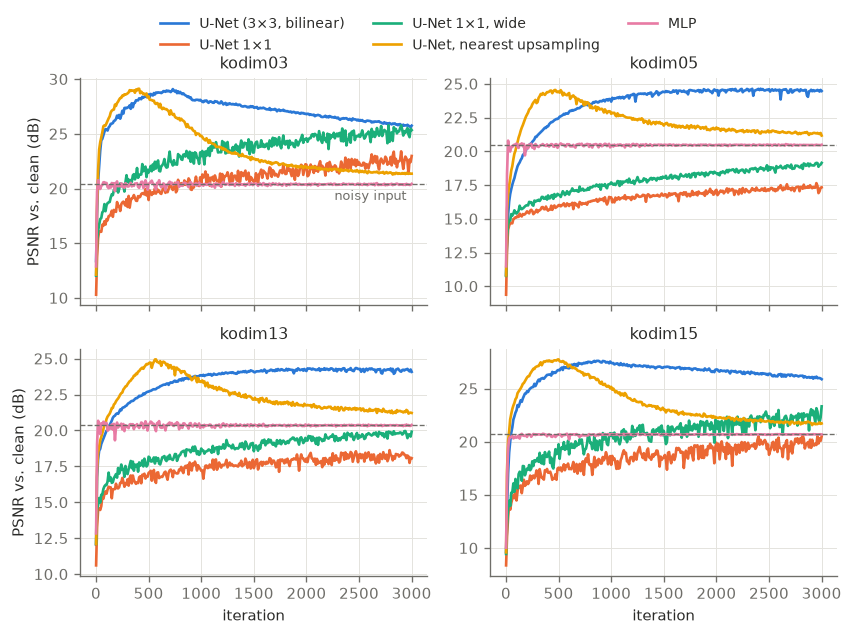

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(7.2, 5.0), sharex=True)
for ax, im in zip(axes.ravel(), IMAGES):
    for m in order:
        g = h3[(h3.model == m) & (h3.image == im)]
        ax.plot(g["iter"], g["psnr_clean"], color=MODEL_COLORS[m], label=MODEL_LABELS[m])
    nb_ = base.loc[base.image == im, "noisy_psnr"].item()
    ax.axhline(nb_, color=MUTED, lw=0.8, ls="--")
    ax.set_title(im)
axes[0, 0].text(2950, base.loc[base.image == "kodim03", "noisy_psnr"].item() - 0.5, "noisy input", color=MUTED, fontsize=8, ha="right", va="top")
for ax in axes[:, 0]:
    ax.set_ylabel("PSNR vs. clean (dB)")
for ax in axes[1]:
    ax.set_xlabel("iteration")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncols=3, bbox_to_anchor=(0.5, 1.06))
fig.tight_layout()
savefig(fig, "h3_curves")

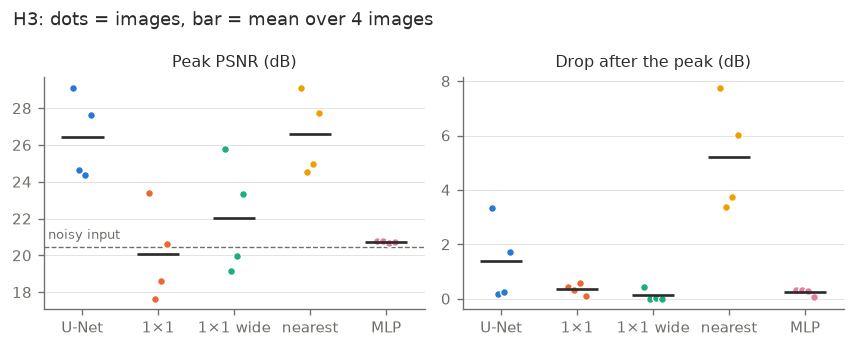

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.9))
xs = np.arange(len(order))
for ax, col, title in [(axes[0], "peak_psnr", "Peak PSNR (dB)"), (axes[1], "drop_psnr", "Drop after the peak (dB)")]:
    for i, m in enumerate(order):
        vals = s3.loc[s3.model == m, col].to_numpy()
        ax.scatter(np.full(len(vals), i) + np.linspace(-0.12, 0.12, len(vals)), vals, s=22,
                   color=MODEL_COLORS[m], edgecolor="white", linewidth=0.8, zorder=3)
        ax.hlines(vals.mean(), i - 0.28, i + 0.28, color=INK, lw=1.6, zorder=4)
    ax.set_xticks(xs, ["U-Net", "1×1", "1×1 wide", "nearest", "MLP"])
    ax.set_title(title)
    ax.grid(axis="x", visible=False)
axes[0].axhline(base["noisy_psnr"].mean(), color=MUTED, lw=0.8, ls="--")
axes[0].text(-0.45, base["noisy_psnr"].mean() + 0.25, "noisy input", color=MUTED, fontsize=8, ha="left", va="bottom")
fig.suptitle("H3: dots = images, bar = mean over 4 images", x=0.02, ha="left")
fig.tight_layout()
savefig(fig, "h3_summary")

**Visual comparison** (`kodim03`, zoomed crop). Each model is shown at the stored snapshot closest to its own PSNR peak.

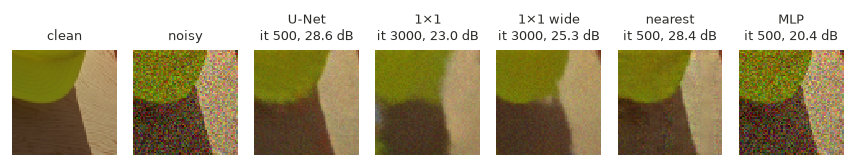

In [7]:
snap_iters = np.array([100, 500, 1000, 2000, 3000])
x = load_image(DATA_DIR / "kodim03.png")
y = add_gaussian_noise(x, 25, seed=0)
r0, c0, s = 120, 30, 64
tiles = [("clean", to_numpy_image(x)), ("noisy", to_numpy_image(y))]
for m in order:
    g = h3[(h3.model == m) & (h3.image == "kodim03")]
    run = g["run"].iloc[0]
    it = int(snap_iters[np.abs(snap_iters - g.loc[g["psnr_clean"].idxmax(), "iter"]).argmin()])
    img = io.imread(RESULTS_DIR / "h3" / "img" / f"{run}_it{it}.png") / 255
    p = g.loc[(g["iter"] - it).abs().idxmin(), "psnr_clean"]
    short = {"unet": "U-Net", "unet_1x1": "1×1", "unet_1x1_wide": "1×1 wide", "unet_nearest": "nearest", "mlp": "MLP"}[m]
    tiles.append((f"{short}\nit {it}, {p:.1f} dB", img))
fig, axes = plt.subplots(1, len(tiles), figsize=(7.2, 1.9))
for ax, (title, img) in zip(axes, tiles):
    ax.imshow(img[r0:r0 + s, c0:c0 + s], interpolation="nearest")
    ax.set_title(title, fontsize=7.5)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for sp in ax.spines.values():
        sp.set_visible(False)
fig.tight_layout()
savefig(fig, "h3_crops")

## Findings

**H3a — spatial kernels: confirmed.**
- With only 1×1 kernels, the mean peak falls by about 6 dB (69k params). With the parameter-matched wide variant (454k params) it still falls by about 4 dB.
- The 1×1 network does not beat the noisy input on average (−0.4 dB), and the wide one only by 1.6 dB. The U-Net gains about 6 dB.
- So the loss is not explained by parameter count.
- This is *against* the prediction from the literature (Heckel & Hand: 1×1 + upsampling suffices). One likely reason: the Deep Decoder upsamples after every layer and has no skip connections. Our 1×1 U-Net can route per-pixel information through the 1×1 skip path, which has no spatial prior.

**H3b — smooth upsampling: refuted for the peak, but it controls the decline.**
- With nearest-neighbour upsampling, the peak is unchanged (≈ 26.6 vs. 26.4 dB).
- But it reaches the peak about 3× earlier (≈ 490 vs. 1620 iterations) and then collapses about 4× harder (≈ 5.2 dB vs. 1.4 dB drop), ending near 21 dB on every image.
- So the 3×3 kernels determine *how good* the best output is. Bilinear upsampling determines *how slowly* noise is fitted afterwards, i.e. how forgiving the stopping point is.

**H3c — no spatial structure: confirmed.**
- The MLP never gets meaningfully above the noisy input (~20.7 dB on every image, +0.3 dB on average).
- It reproduces the noisy image almost immediately: training MSE ≈ 0.0002 by iteration 500, far below σ² ≈ 0.0096.

**Caveat.**
- The 1×1 variants are still *rising* at iteration 3000 (see the curves), i.e. they are much slower to fit anything.
- "Weaker prior" and "slower optimisation" are therefore not fully separated. A longer run of `unet_1x1_wide` would be needed to rule out the second explanation.